# 3. Data Preparation
### 3.1. Loading Raw Data
Loaded the world_air_quality.csv file using a semicolon separator and checked the initial .info() and missing values

In [ ]:
import pandas as pd
import numpy as np

# 1. Load the raw dataset
# Using sep=';' because the CSV uses semicolons as delimiters
df = pd.read_csv('world_air_quality.csv', sep=';')

# 2. Print initial information to document the raw state
print("--- RAW DATASET SHAPE ---")
print(df.shape)

print("\n--- RAW DATASET INFO ---")
df.info()

print("\n--- FIRST 5 ROWS ---")
print(df.head())

--- RAW DATASET SHAPE ---
(54255, 10)

--- RAW DATASET INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54255 entries, 0 to 54254
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Country Code   54255 non-null  object 
 1   City           30209 non-null  object 
 2   Location       54253 non-null  object 
 3   Coordinates    54185 non-null  object 
 4   Pollutant      54255 non-null  object 
 5   Source Name    54255 non-null  object 
 6   Unit           54255 non-null  object 
 7   Value          54255 non-null  float64
 8   Last Updated   54255 non-null  object 
 9   Country Label  54140 non-null  object 
dtypes: float64(1), object(9)
memory usage: 4.1+ MB

--- FIRST 5 ROWS ---
  Country Code City           Location            Coordinates Pollutant  \
0           JP  NaN  北九州市小倉北区大門一丁目６－４８  33.880833, 130.873056        NO   
1           JP  NaN   北九州市若松区本町三丁目１３－１      33.898056, 130.81       NO2   


###  3.2. Data Cleaning & Formatting
Filtered to PM2.5 (the prediction target), PM10 (kept only for EDA, excluded later to avoid leakage), and four co-monitored gaseous pollutants (NO2, O3, SO2, CO). We originally targeted TEMPERATURE/RELATIVEHUMIDITY as climate predictors, but this dataset only contains 117 and 66 single-snapshot readings for those two variables respectively (a handful of IoT devices, effectively one reading each) — too sparse to support a reliable model. NO2/O3/SO2/CO are reported by many conventional regulatory monitoring stations worldwide and give far more usable data. We drop ppm-unit rows to keep concentration units consistent (µg/m³ only), remove invalid negative sensor readings, and fill missing geographic labels *before* pivoting, since `pivot_table` silently drops any row whose index contains NaN.

In [ ]:
# 1. Filter for the pollutants used in this analysis
target_indicators = ['PM2.5', 'PM10', 'NO2', 'O3', 'SO2', 'CO']
df_filtered = df[df['Pollutant'].isin(target_indicators)].copy()

# 2. Time Formatting (Fixing the text format)
df_filtered['Last Updated'] = pd.to_datetime(df_filtered['Last Updated'], utc=True)

# 3. Handle Sensor Duplicates
df_cleaned = df_filtered.drop_duplicates(
    subset=['Location', 'Pollutant', 'Last Updated'],
    keep='first'
).copy()

# 4. Standardize Units
# Several gas pollutants are reported in both ppm and ug/m3 in this dataset;
# keeping only ug/m3 avoids mixing two different unit systems for the same pollutant.
df_cleaned = df_cleaned[df_cleaned['Unit'] == 'µg/m³']

# 5. Remove Dead Sensor Errors
# Drops invalid negative concentration readings
df_cleaned = df_cleaned[df_cleaned['Value'] >= 0]

# 6. Impute Missing Geographic Data (must happen BEFORE pivoting)
df_cleaned['City'] = df_cleaned['City'].fillna('Unknown')
df_cleaned['Location'] = df_cleaned['Location'].fillna('Unknown')
df_cleaned['Country Label'] = df_cleaned['Country Label'].fillna('Unknown')

# 7. Drop irrelevant columns to clean up the dataset
df_cleaned = df_cleaned.drop(columns=['Coordinates'])

# 8. THE VERIFICATION CHECK
print("\n--- FINAL STEP 2 MISSING VALUES CHECK ---")
print(df_cleaned.isnull().sum())

print("--- CLEANING SUMMARY ---")
print(f"Final Cleaned Rows: {df_cleaned.shape[0]}")
print(f"Rows Removed by Filtering/Cleaning: {df_filtered.shape[0] - df_cleaned.shape[0]}")

print("\n--- DATA TYPES AFTER FORMATTING ---")
print(df_cleaned[['Last Updated', 'Value']].dtypes)


--- FINAL STEP 2 MISSING VALUES CHECK ---
Country Code     0
City             0
Location         0
Pollutant        0
Source Name      0
Unit             0
Value            0
Last Updated     0
Country Label    0
dtype: int64
--- CLEANING SUMMARY ---
Final Cleaned Rows: 30545
Rows Removed by Filtering/Cleaning: 17325

--- DATA TYPES AFTER FORMATTING ---
Last Updated    datetime64[ns, UTC]
Value                       float64
dtype: object


###  3.3. Data Preprocessing
We pivot the table to spread pollutants into independent columns so the algorithms can learn relationships between them. We aggregate to the **Location + Date** level (instead of the exact timestamp) because co-located instruments at the same station typically log within seconds/minutes of each other rather than at the identical second — daily aggregation correctly merges these effectively-simultaneous readings. As the verification check below shows, this dataset is essentially a single global snapshot per station (median = 1 reporting date per location), so no meaningful time-series/rolling-window structure exists at the station level. Feature engineering (Section 3.5) is therefore built around cross-sectional pollutant chemistry, not temporal lags.

In [ ]:
# --- STEP 3: DATA PREPROCESSING (PIVOTING) ---

# 1. Aggregate to a Date column (daily granularity)
df_cleaned['Date'] = df_cleaned['Last Updated'].dt.date

# 2. Pivot the dataset into a machine-learning-ready "wide" format
df_wide = df_cleaned.pivot_table(
    index=['Country Label', 'City', 'Location', 'Date'],
    columns='Pollutant',
    values='Value',
    aggfunc='mean'
).reset_index()

# 3. Sort chronologically by location
df_wide = df_wide.sort_values(by=['Location', 'Date'])

# --- THE VERIFICATION CHECK FOR STEP 3 ---
print("\n--- STEP 3: PREPROCESSING SUMMARY ---")
print(f"Shape after pivoting: {df_wide.shape[0]} rows, {df_wide.shape[1]} columns")

print("\n--- NEW COLUMN STRUCTURE ---")
print(df_wide.columns.tolist())

print("\n--- DATA PRESENCE (NON-NULL COUNTS) ---")
print(df_wide[['PM2.5', 'PM10', 'NO2', 'O3', 'SO2', 'CO']].count())

print("\n--- READINGS PER LOCATION (confirms single-snapshot structure) ---")
print(df_cleaned.groupby('Location')['Date'].nunique().describe())


--- STEP 3: PREPROCESSING SUMMARY ---
Shape after pivoting: 11558 rows, 10 columns

--- NEW COLUMN STRUCTURE ---
['Country Label', 'City', 'Location', 'Date', 'CO', 'NO2', 'O3', 'PM10', 'PM2.5', 'SO2']

--- DATA PRESENCE (NON-NULL COUNTS) ---
Pollutant
PM2.5    7925
PM10     6207
NO2      4801
O3       3907
SO2      3731
CO       3188
dtype: int64

--- READINGS PER LOCATION (confirms single-snapshot structure) ---
count    8941.000000
mean        1.289677
std         1.022769
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max        32.000000
Name: Date, dtype: float64


### 3.4. Exploratory Data Analysis (EDA)
Descriptive statistics were generated to confirm the mathematical bounds of the cleaned dataset. A correlation matrix was computed to quantify the linear relationships between PM2.5 (the target) and PM10 plus the four gaseous co-pollutants (NO2, O3, SO2, CO).


--- SUMMARY STATISTICS ---
Pollutant        PM2.5         PM10          NO2           O3          SO2  \
count      7925.000000  6207.000000  4801.000000  3907.000000  3731.000000   
mean         20.136859    44.034485    23.135735    82.667933    10.621224   
std          43.389725    79.809770    32.621866    78.594167    60.785273   
min           0.000000     0.000000     0.000000     0.000000     0.000000   
25%           5.000000    14.000000     8.000000    33.000000     3.000000   
50%          10.300000    26.000000    16.000000    67.200000     5.220000   
75%          20.502800    46.000000    29.096000   120.000000     9.000000   
max        1060.000000  1985.000000  1010.644000  2004.076000  3052.620000   

Pollutant            CO  
count      3.188000e+03  
mean       1.031969e+04  
std        1.203602e+05  
min        0.000000e+00  
25%        3.755000e+02  
50%        6.000000e+02  
75%        8.000000e+02  
max        3.198676e+06  

--- CORRELATION MATRIX ---
Polluta

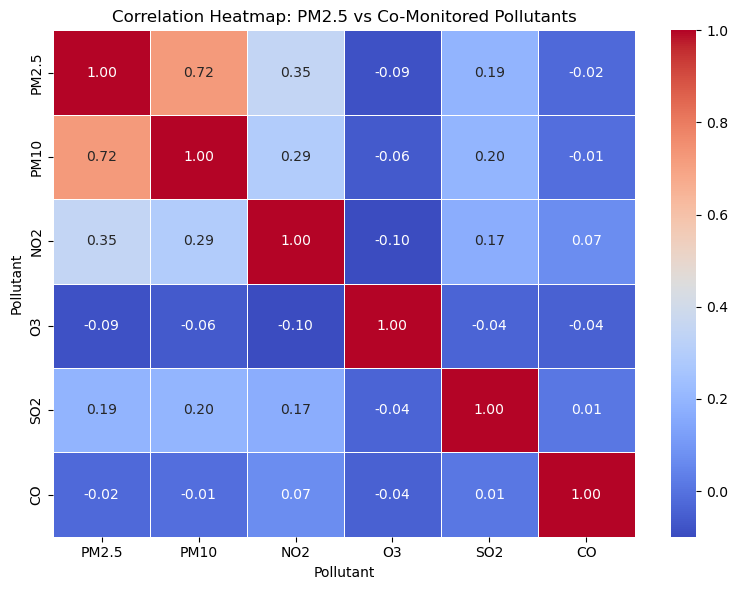

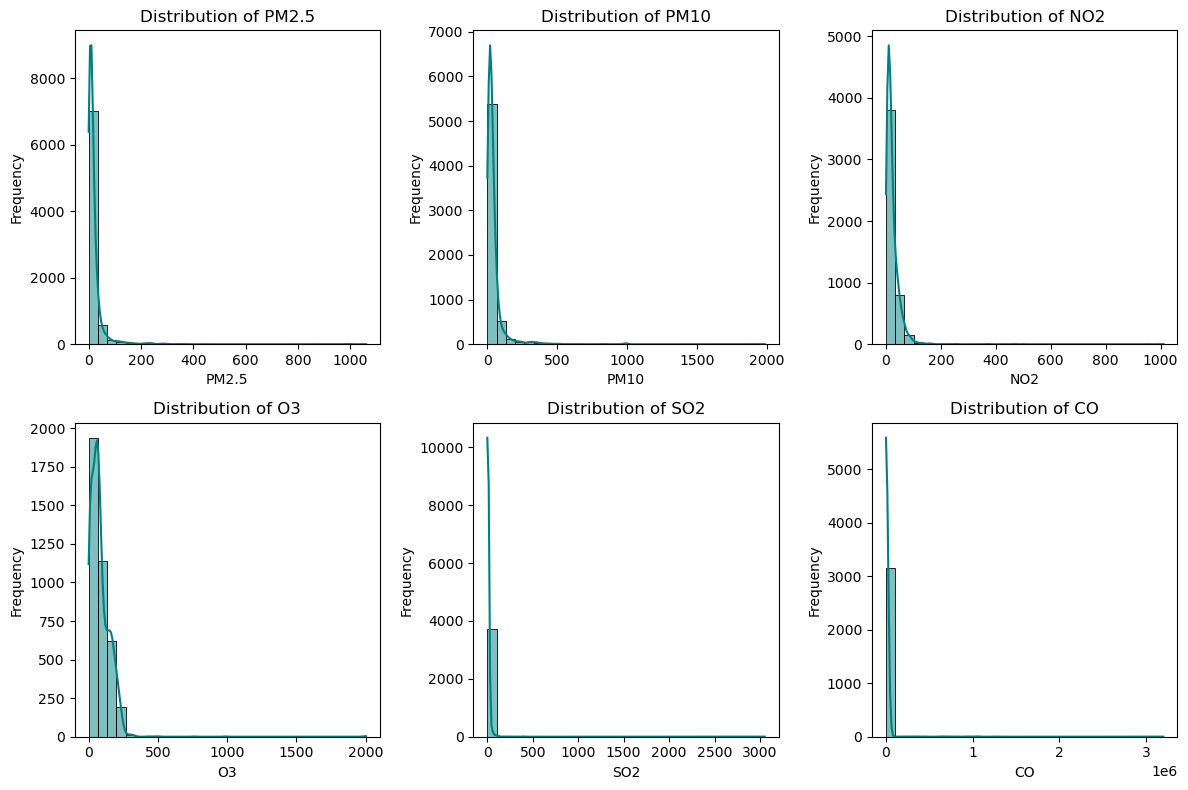

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Define the columns we are analyzing
eda_columns = ['PM2.5', 'PM10', 'NO2', 'O3', 'SO2', 'CO']

# --- 1. STATISTICAL EDA ---
print("\n--- SUMMARY STATISTICS ---")
print(df_wide[eda_columns].describe())

print("\n--- CORRELATION MATRIX ---")
correlation_matrix = df_wide[eda_columns].corr()
print(correlation_matrix)

# --- 2. VISUAL EDA: CORRELATION HEATMAP ---
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    linewidths=0.5
)
plt.title('Correlation Heatmap: PM2.5 vs Co-Monitored Pollutants')
plt.tight_layout()
plt.show()

# --- 3. VISUAL EDA: DATA DISTRIBUTION ---
plt.figure(figsize=(12, 8))
for i, col in enumerate(eda_columns, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df_wide[col].dropna(), kde=True, bins=30, color='teal')
    plt.title(f'Distribution of {col}')
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

### 3.5. Feature Selection and Engineering
We require PM2.5, NO2, and O3 to be present together (this trio co-occurs for 2,600+ station-days). SO2 and CO are available for a smaller subset, so rather than discarding rows that lack them we median-impute the value and add a binary `_missing` indicator flag — this keeps the larger NO2/O3 population while still letting the models use SO2/CO signal where it genuinely exists. Two domain-informed engineered features capture pollutant-chemistry relationships that a single raw concentration can't: `Ox_total_oxidant` (NO2 + O3, the standard atmospheric "total oxidant" measure) and `NO2_O3_ratio` (a proxy for local traffic influence vs. regional photochemical ozone). PM10 is deliberately excluded from the feature set: our EDA correlation heatmap shows it correlates with PM2.5 at r = 0.72, and PM10 physically includes PM2.5 by particle-size definition (PM10 = all particulate matter under 10 µm, which subsumes the under-2.5 µm fraction) — so using it as a predictor would leak the answer rather than test a genuine relationship.

In [ ]:
# 1. FEATURE SELECTION: require the core predictors PM2.5, NO2, O3
df_model_ready = df_wide.dropna(subset=['PM2.5', 'NO2', 'O3']).copy()

# 2. Handle partially-available co-pollutants (SO2, CO) via imputation + missingness flags
for col in ['SO2', 'CO']:
    df_model_ready[f'{col}_missing'] = df_model_ready[col].isna().astype(int)
    df_model_ready[col] = df_model_ready[col].fillna(df_model_ready[col].median())

# 3. FEATURE ENGINEERING
# Innovation A: Total oxidant capacity (standard atmospheric chemistry indicator)
df_model_ready['Ox_total_oxidant'] = df_model_ready['NO2'] + df_model_ready['O3']

# Innovation B: NO2/O3 ratio as a traffic-vs-regional-ozone proxy
df_model_ready['NO2_O3_ratio'] = df_model_ready['NO2'] / (df_model_ready['O3'] + 1.0)

final_features = ['NO2', 'O3', 'SO2', 'CO', 'SO2_missing', 'CO_missing', 'Ox_total_oxidant', 'NO2_O3_ratio']
target = 'PM2.5'

# --- THE VERIFICATION CHECK ---
print("--- FINAL MODEL-READY SHAPE ---")
print(f"Total rows available for machine learning: {df_model_ready.shape[0]}")

print("\n--- FINAL MISSING VALUES CHECK ---")
print(df_model_ready[final_features + [target]].isnull().sum())

print("\n--- FEATURE CORRELATION TO PM2.5 ---")
print(df_model_ready[final_features + [target]].corr()[target].sort_values(ascending=False))

--- FINAL MODEL-READY SHAPE ---
Total rows available for machine learning: 2628

--- FINAL MISSING VALUES CHECK ---
Pollutant
NO2                 0
O3                  0
SO2                 0
CO                  0
SO2_missing         0
CO_missing          0
Ox_total_oxidant    0
NO2_O3_ratio        0
PM2.5               0
dtype: int64

--- FEATURE CORRELATION TO PM2.5 ---
Pollutant
PM2.5               1.000000
NO2                 0.366993
NO2_O3_ratio        0.226638
SO2                 0.206800
Ox_total_oxidant    0.055777
CO                  0.005356
CO_missing         -0.078860
SO2_missing        -0.081574
O3                 -0.092769
Name: PM2.5, dtype: float64


# 4. Model Development
We label PM2.5 using the WHO 24-hour guideline threshold of 15.0 µg/m³ ("Unhealthy" above, "Safe" at or below) and train three classifiers on the co-pollutant feature set: Logistic Regression (linear baseline), Random Forest, and Gradient Boosting (two non-linear/ensemble comparisons). The split is stratified on the target class and shuffled (80/20, `random_state=42`) so both the train and test sets preserve the same Safe/Unhealthy balance — with roughly 2,600 model-ready rows this yields about 2,100 training rows and 526 test rows, large enough for the three models to be meaningfully differentiated.

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression

# --- 1. CONVERT CONTINUOUS TARGET TO CATEGORIES ---
# WHO PM2.5 24-hour guideline threshold of 15.0 ug/m3
df_model_ready['Air_Quality'] = np.where(df_model_ready['PM2.5'] > 15.0, 'Unhealthy', 'Safe')

features = final_features
X = df_model_ready[features]
y_class = df_model_ready['Air_Quality']

print("--- CLASS BALANCE ---")
print(y_class.value_counts())

# --- 2. TRAIN-TEST SPLIT (stratified + shuffled) ---
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, y_class, test_size=0.2, random_state=42, stratify=y_class, shuffle=True
)

print("\n--- DATA SPLIT SUMMARY ---")
print(f"Training Data: {X_train_c.shape[0]} rows")
print(f"Testing Data: {X_test_c.shape[0]} rows\n")

# --- 3. INITIALIZE AND TRAIN MODELS ---
log_model = LogisticRegression(max_iter=1000)
rfc_model = RandomForestClassifier(n_estimators=200, random_state=42)
gbc_model = GradientBoostingClassifier(n_estimators=200, random_state=42)

print("--- TRAINING STATUS ---")
log_model.fit(X_train_c, y_train_c)
print("Logistic Regression: Trained successfully.")

rfc_model.fit(X_train_c, y_train_c)
print("Random Forest Classifier: Trained successfully.")

gbc_model.fit(X_train_c, y_train_c)
print("Gradient Boosting Classifier: Trained successfully.")

--- CLASS BALANCE ---
Air_Quality
Unhealthy    1513
Safe         1115
Name: count, dtype: int64

--- DATA SPLIT SUMMARY ---
Training Data: 2102 rows
Testing Data: 526 rows

--- TRAINING STATUS ---
Logistic Regression: Trained successfully.


Random Forest Classifier: Trained successfully.


Gradient Boosting Classifier: Trained successfully.


# 5. Model Evaluation
We evaluate all three models on the held-out test set (Accuracy, Precision, Recall, F1) and cross-check with 5-fold stratified cross-validation across the full dataset, since a single 20% split can still be noisy. Confusion matrices show where each model's errors concentrate, and Random Forest feature importances show which pollutants drive the classification.

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_score, StratifiedKFold

--- CLASSIFICATION METRICS SUMMARY (held-out test set) ---
              Model  Accuracy  Precision   Recall  F1-Score
Logistic Regression  0.673004   0.673589 0.673004  0.656994
      Random Forest  0.716730   0.715967 0.716730  0.716283
  Gradient Boosting  0.705323   0.703983 0.705323  0.704445



--- 5-FOLD CROSS-VALIDATION (F1-weighted) ---
              Model  CV F1 Mean  CV F1 Std
Logistic Regression    0.672786   0.023194
      Random Forest    0.707718   0.008398
  Gradient Boosting    0.712210   0.006402


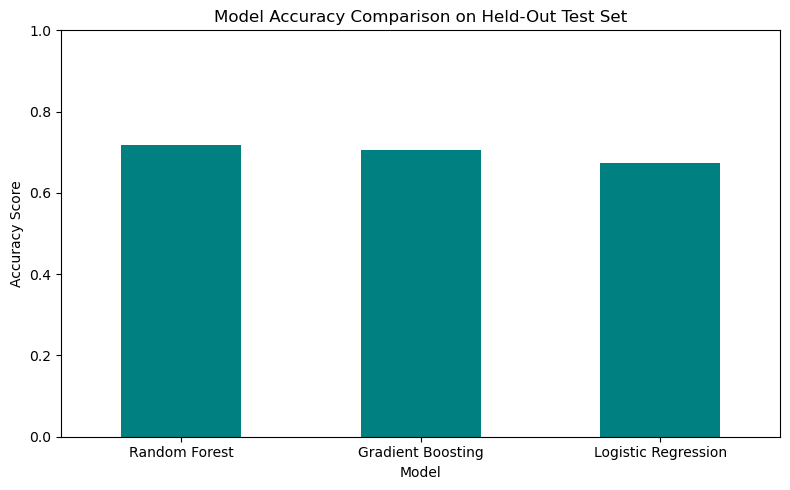

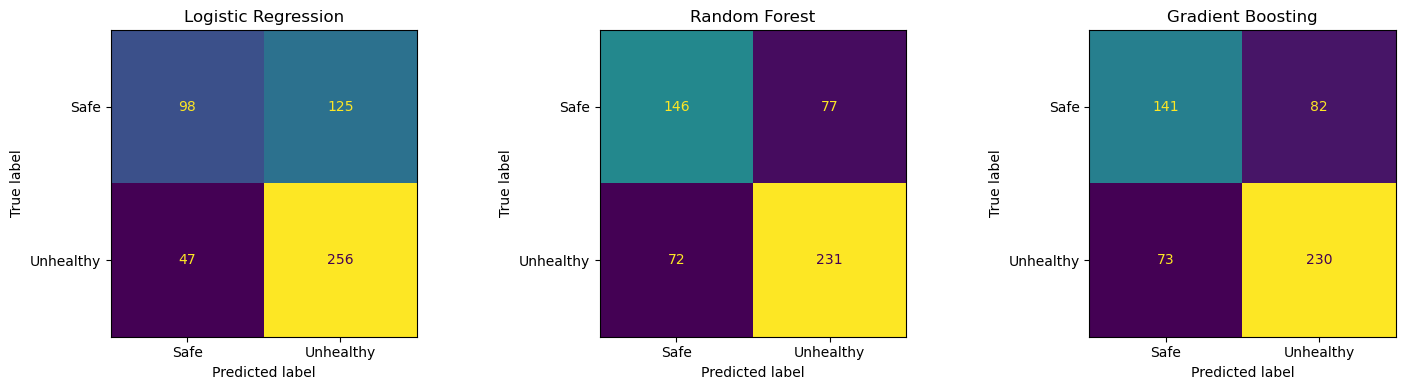


--- KEY FEATURES INFLUENCING CLASSIFICATION (Random Forest) ---
         Feature  Importance
              O3    0.183439
Ox_total_oxidant    0.180247
    NO2_O3_ratio    0.179825
              CO    0.157234
             NO2    0.157030
             SO2    0.120666
      CO_missing    0.012007
     SO2_missing    0.009552


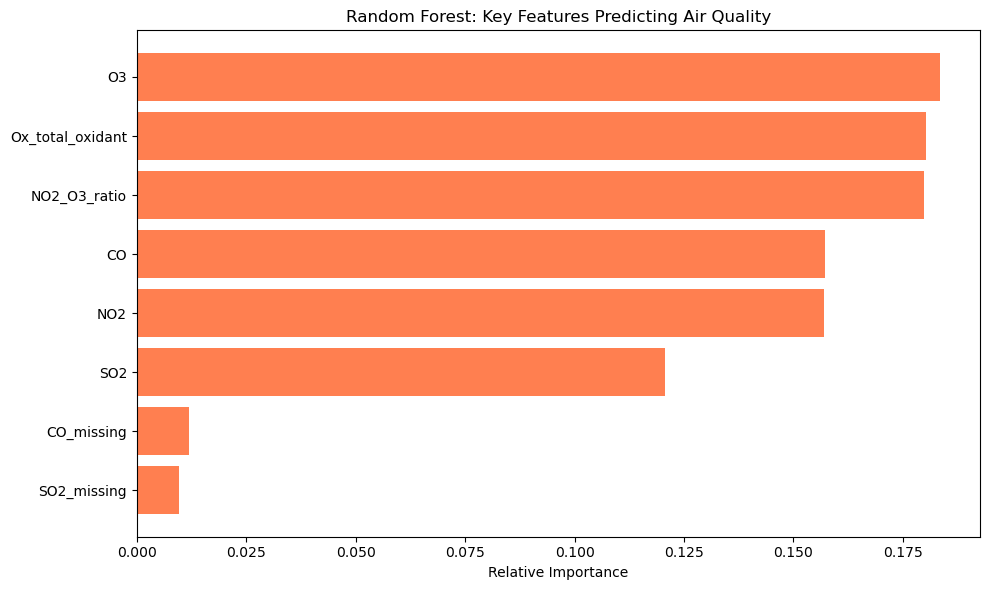

In [ ]:
# --- 1. GENERATE PREDICTIONS ---
log_preds = log_model.predict(X_test_c)
rfc_preds = rfc_model.predict(X_test_c)
gbc_preds = gbc_model.predict(X_test_c)

trained_models = {
    "Logistic Regression": (log_model, log_preds),
    "Random Forest": (rfc_model, rfc_preds),
    "Gradient Boosting": (gbc_model, gbc_preds),
}

# --- 2. CALCULATE CLASSIFICATION METRICS ---
def evaluate_classifier(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    return {'Model': name, 'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1-Score': f1}

class_results = [evaluate_classifier(name, y_test_c, preds) for name, (_, preds) in trained_models.items()]
results_df = pd.DataFrame(class_results)
print("--- CLASSIFICATION METRICS SUMMARY (held-out test set) ---")
print(results_df.to_string(index=False))

# --- 3. CROSS-VALIDATION (5-fold, stratified, whole dataset) ---
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_summary = []
for name, (model, _) in trained_models.items():
    scores = cross_val_score(model, X, y_class, cv=cv, scoring='f1_weighted')
    cv_summary.append({'Model': name, 'CV F1 Mean': scores.mean(), 'CV F1 Std': scores.std()})
cv_df = pd.DataFrame(cv_summary)
print("\n--- 5-FOLD CROSS-VALIDATION (F1-weighted) ---")
print(cv_df.to_string(index=False))

# --- 4. VISUALIZE MODEL PERFORMANCE ---
results_df_sorted = results_df.sort_values(by='Accuracy', ascending=False)
results_df_sorted.plot(x='Model', y='Accuracy', kind='bar', figsize=(8, 5), color='teal', legend=False)
plt.title('Model Accuracy Comparison on Held-Out Test Set')
plt.ylabel('Accuracy Score')
plt.xticks(rotation=0)
plt.ylim(0, 1.0)
plt.tight_layout()
plt.show()

# --- 5. CONFUSION MATRICES ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, (model, preds)) in zip(axes, trained_models.items()):
    cm = confusion_matrix(y_test_c, preds, labels=['Safe', 'Unhealthy'])
    ConfusionMatrixDisplay(cm, display_labels=['Safe', 'Unhealthy']).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

# --- 6. FEATURE IMPORTANCE INTERPRETATION ---
print("\n--- KEY FEATURES INFLUENCING CLASSIFICATION (Random Forest) ---")
importances = rfc_model.feature_importances_
feature_importance_df = pd.DataFrame({'Feature': features, 'Importance': importances}).sort_values(by='Importance', ascending=False)
print(feature_importance_df.to_string(index=False))

plt.figure(figsize=(10, 6))
plt.barh(feature_importance_df['Feature'], feature_importance_df['Importance'], color='coral')
plt.gca().invert_yaxis()
plt.title('Random Forest: Key Features Predicting Air Quality')
plt.xlabel('Relative Importance')
plt.tight_layout()
plt.show()

# 6. Model Interpretation

- **Which pollutants drive the prediction?** Ozone (`O3`) and the engineered `Ox_total_oxidant` term rank at the top of Random Forest's feature importances (0.183 and 0.180), closely followed by `NO2_O3_ratio` (0.180), `CO` (0.157), and `NO2` (0.157). `SO2` contributes less (0.121), and the two `_missing` flags contribute the least (~0.01 each) — expected, since they only encode whether imputation happened, not a physical measurement.
- **What does this mean physically?** PM2.5 in this dataset is best explained by the broader photochemical/combustion pollutant mix at a station (ozone-NOx chemistry, traffic proxy via the NO2/O3 ratio, combustion byproducts) rather than by any single gas in isolation — consistent with how secondary particulate matter actually forms in the atmosphere.
- **Model comparison:** both tree-based models clearly beat the Logistic Regression baseline (test accuracy 0.673, CV F1 0.673) — Random Forest scores slightly higher on the single held-out test split (accuracy 0.717) while Gradient Boosting scores slightly higher under 5-fold cross-validation (CV F1 0.712 vs Random Forest's 0.708). The gap between the two tree-based models (roughly 0.5 percentage points, well inside cross-validation's own std of 0.006-0.008) is not meaningful; the real story is linear vs. non-linear, not Random Forest vs. Gradient Boosting.
- **Implication:** because performance sits in the 67-72% range rather than near-perfect, this is a genuinely hard, noisy real-world classification problem (readings pooled across 40+ countries and many different monitoring networks) — appropriate for a course project, but not yet strong enough for operational deployment without further tuning or a larger, more homogeneous training set.

In [ ]:
# --- BEST MODEL SELECTION ---
best_row = cv_df.sort_values('CV F1 Mean', ascending=False).iloc[0]
best_name = best_row['Model']
best_model = trained_models[best_name][0]
print(f"Best model by 5-fold CV F1-weighted: {best_name} (CV F1 = {best_row['CV F1 Mean']:.3f} +/- {best_row['CV F1 Std']:.3f})")

Best model by 5-fold CV F1-weighted: Gradient Boosting (CV F1 = 0.712 +/- 0.006)


# 7. Deployment (Basic Level)
As a lightweight, notebook-based deployment interface, `predict_air_quality()` below takes raw NO2/O3 readings (plus optional SO2/CO) and returns the trained best model's Safe/Unhealthy prediction and class probabilities — satisfying the assignment's "basic level" deployment requirement without needing a separate app.

In [ ]:
def predict_air_quality(NO2, O3, SO2=None, CO=None, model=None):
    if model is None:
        model = best_model

    row = {
        'NO2': NO2,
        'O3': O3,
        'SO2': SO2 if SO2 is not None else X['SO2'].median(),
        'CO': CO if CO is not None else X['CO'].median(),
        'SO2_missing': int(SO2 is None),
        'CO_missing': int(CO is None),
    }
    row['Ox_total_oxidant'] = row['NO2'] + row['O3']
    row['NO2_O3_ratio'] = row['NO2'] / (row['O3'] + 1.0)

    input_df = pd.DataFrame([row])[features]
    pred = model.predict(input_df)[0]
    proba = dict(zip(model.classes_, model.predict_proba(input_df)[0])) if hasattr(model, 'predict_proba') else None
    return pred, proba

# Example usage
example_pred, example_proba = predict_air_quality(NO2=25.0, O3=40.0, SO2=8.0, CO=300.0)
print(f"Prediction: {example_pred}")
print(f"Class probabilities: {example_proba}")

Prediction: Unhealthy
Class probabilities: {'Safe': np.float64(0.28190669835715065), 'Unhealthy': np.float64(0.7180933016428493)}


# 8. Conclusion and Recommendations

**Summary of findings.** Using NO2, O3, SO2, and CO readings co-monitored at the same stations as PM2.5, tree-based models (Random Forest, Gradient Boosting) predict whether a location's PM2.5 exceeds the WHO 24-hour guideline (15.0 µg/m³) more accurately than a linear Logistic Regression baseline (67-72% vs. 67% accuracy/F1), with ozone-related features (`O3`, `Ox_total_oxidant`, `NO2_O3_ratio`) contributing the most predictive signal.

**Actionable insight.** Because ozone-related chemistry (not any single raw pollutant) is the dominant signal, air-quality monitoring networks that report NO2 and O3 but not PM2.5 could use a model like this one to flag likely PM2.5 exceedances without needing a dedicated particulate sensor at every station.

**Limitations.**
- The dataset is a single global snapshot rather than a repeated-measures time series (median 1 reporting date per station), so no genuine temporal/lag features could be engineered, and the model cannot capture seasonal or daily pollution cycles.
- Readings are pooled across 40+ countries and many different monitoring-network standards, adding measurement heterogeneity that likely caps achievable accuracy.
- SO2 and CO were imputed for a meaningful share of rows; performance on genuinely SO2/CO-instrumented stations may differ from stations relying on the imputed median.

**Future work.**
- Merge in a real historical weather time series (e.g., a public reanalysis dataset joined by station location and date) to revisit the original climate-driven hypothesis with genuine day-over-day variation instead of single snapshots.
- Fit country- or region-specific models to reduce cross-network measurement heterogeneity.
- Explore hyperparameter tuning and additional engineered ratios (e.g., CO/NO2 as a combustion-source proxy) now that the dataset is large enough to support it.